# Remarketing Planner - walkthrough

In [1]:
import sys; sys.path.insert(0, '../src')
from remarketing_planner import data, model
P = data.load_params(); N = P['cohort']
T = P['types']['applied']
rows = model.simulate(model.type_params(P, 'applied'), T['sched'])
s = model.summarize(rows, N)
print(f"net {s['net']:,.0f}  ROI {s['roi']:.2f}  revenue in 24h {model.rev_share(rows, 1):.0%}")
assert round(s['net']) == 9808

net 9,808  ROI 2.56  revenue in 24h 61%


In [2]:
import pandas as pd
out = []
for k, t in P['types'].items():
    tp = model.type_params(P, k)
    r = lambda sched: model.summarize(model.simulate(tp, sched), N)['net']
    out.append({'segment': k, 'front-loaded': r(t['sched']), 'weekly': r(model.flat_sched()), 'aggressive': r(model.agg_sched())})
print(pd.DataFrame(out).round(0).to_string(index=False))

segment  front-loaded  weekly  aggressive
applied        9808.0  4892.0      9979.0
  first        9725.0  5295.0      8573.0
   fail        -185.0   932.0     -1358.0
  asnef         646.0  1349.0       -44.0
     hq       28096.0 14646.0     36438.0
   cold        -581.0  1890.0      -657.0


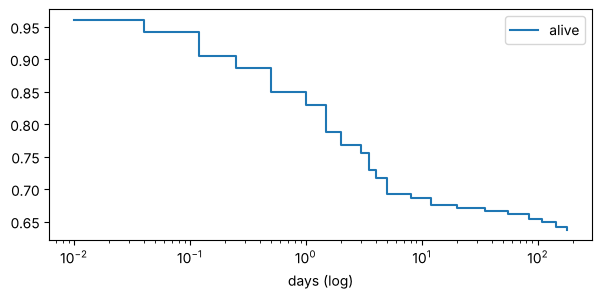

In [3]:
import matplotlib.pyplot as plt
ax = pd.DataFrame({'alive': [r['aliveOut'] for r in rows]}, index=[r['t'] for r in rows]).plot(drawstyle='steps-post', figsize=(7,3), logx=True); ax.set_xlabel('days (log)'); plt.show()